In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
# Sklearn
from sklearn.feature_extraction.text import CountVectorizer

from unidecode import unidecode

# WordCloud
from wordcloud import WordCloud

import pickle
# Charger
with open('../data/processed/data.pkl', 'rb') as f:
    data = pickle.load(f)

FINAL_STOPWORDS = data['FINAL_STOPWORDS']

In [ ]:
# Chargement du fichier CSV
test_df = pd.read_csv("../data/processed/test.csv")
# Vérification de 5 lignes au hasard
print(test_df.columns.tolist())
test_df.head(5)

In [ ]:
# Chargement du fichier CSV
train_df = pd.read_csv("../data/processed/train.csv")

# Vérification de 5 lignes au hasard
print(train_df.columns.tolist())
train_df.head(5)

In [64]:
# a. Infos générales

print("Infos générales :")
train_df.info()
print("\n Statistiques descriptives :")
print(train_df.describe(include='all'))

# b. Valeurs manquantes
print("\n Valeurs manquantes par colonne :")
print(train_df.isnull().sum())

# c. Doublons
n_dup = train_df.duplicated().sum()
print(f"\n Nombre de doublons : {n_dup}")
if n_dup > 0:
    train_df = train_df.drop_duplicates()
    print(f"Doublons supprimés. Nouvelle taille : {train_df.shape}")
else:
    print(f"Pas de doublons. Taille du dataset : {train_df.shape}")

# d. Vérification des notes
print("\n Notes uniques avant filtrage :", train_df['label'].unique())
train_df = train_df[train_df['label'].isin([1,2,3,4,5])]
print("Notes après filtrage :", train_df['label'].unique())

# e. Longueur des avis
train_df["review_length"] = train_df["review_text"].str.len()
print("\n Stats sur la longueur des avis :")
print(train_df['review_length'].describe())
print("\nAvis très courts (<10 caractères) :")
print(train_df[train_df['review_length'] < 10].head())


Infos générales :
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7238 entries, 0 to 7237
Data columns (total 24 columns):
 #   Column         Non-Null Count  Dtype              
---  ------         --------------  -----              
 0   review_text    7238 non-null   object             
 1   label          7238 non-null   int64              
 2   rating         7238 non-null   int64              
 3   title          7238 non-null   object             
 4   company        0 non-null      float64            
 5   category       7238 non-null   object             
 6   source         7238 non-null   object             
 7   datetime       7238 non-null   datetime64[ns, UTC]
 8   category_slug  7238 non-null   object             
 9   product_slug   7238 non-null   object             
 10  text_dl        7238 non-null   object             
 11  flag_url       7238 non-null   int64              
 12  flag_email     7238 non-null   int64              
 13  flag_order     7238 non-null  

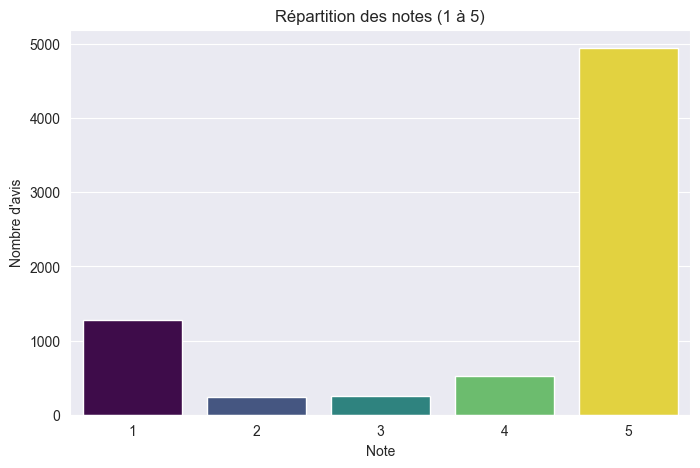

In [9]:
plt.figure(figsize=(8,5))
sns.countplot(x='label', data=train_df, palette='viridis', hue='label', legend=False)
plt.title('Répartition des notes (1 à 5)')
plt.xlabel('Note')
plt.ylabel("Nombre d'avis")
plt.show()

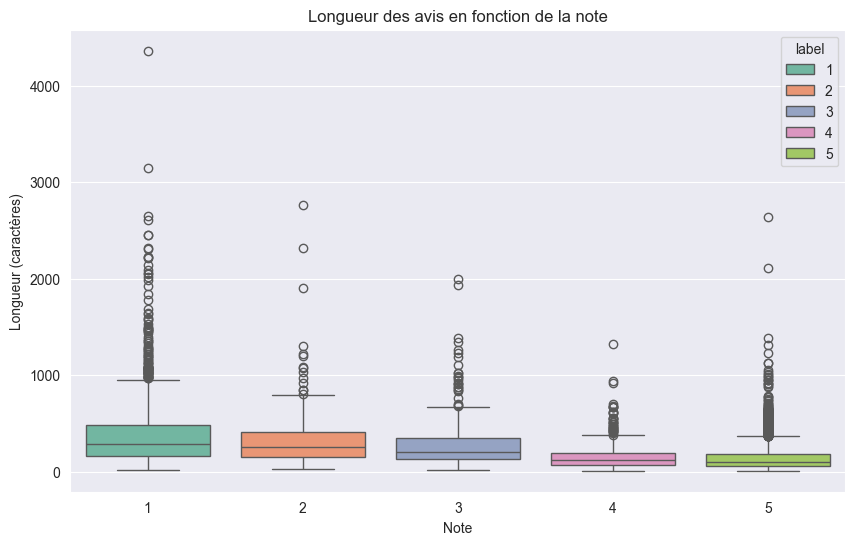

In [10]:
plt.figure(figsize=(10,6))
sns.boxplot(x='label', y='review_length', hue='label', data=train_df, palette='Set2', dodge=False)
plt.title('Longueur des avis en fonction de la note')
plt.xlabel('Note')
plt.ylabel('Longueur (caractères)')
plt.show()

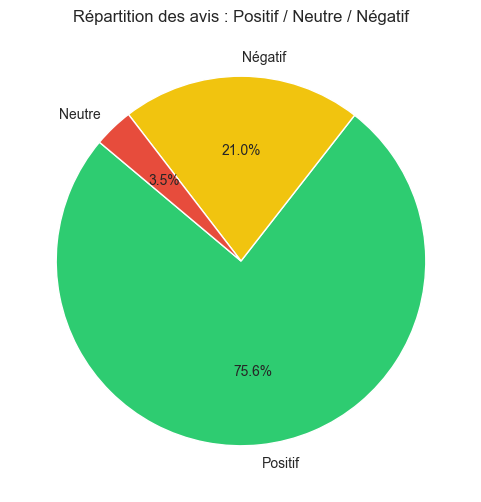

In [11]:
# Création d'une colonne polarité
def label_sentiment(label):
    if label >= 4: return 'Positif'
    elif label == 3: return 'Neutre'
    else: return 'Négatif'

train_df['sentiment'] = train_df['label'].apply(label_sentiment)

# Pie chart
plt.figure(figsize=(6,6))
train_df['sentiment'].value_counts().plot.pie(
    autopct='%1.1f%%', startangle=140, colors=['#2ecc71','#f1c40f','#e74c3c'])
plt.title("Répartition des avis : Positif / Neutre / Négatif")
plt.ylabel("")
plt.show()

### d) Distribution temporelle des avis

Objectif : analyser l'évolution du volume d'avis au cours du temps.
NB: nécessite que la colonne 'datetime' ait été conservée dans df_raw.

/var/folders/zs/w920yp5j4cjfvly1235g5b_40000gn/T/ipykernel_74548/435713691.py:5: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  train_df["date"] = train_df["datetime"].dt.to_period("M").dt.to_timestamp()


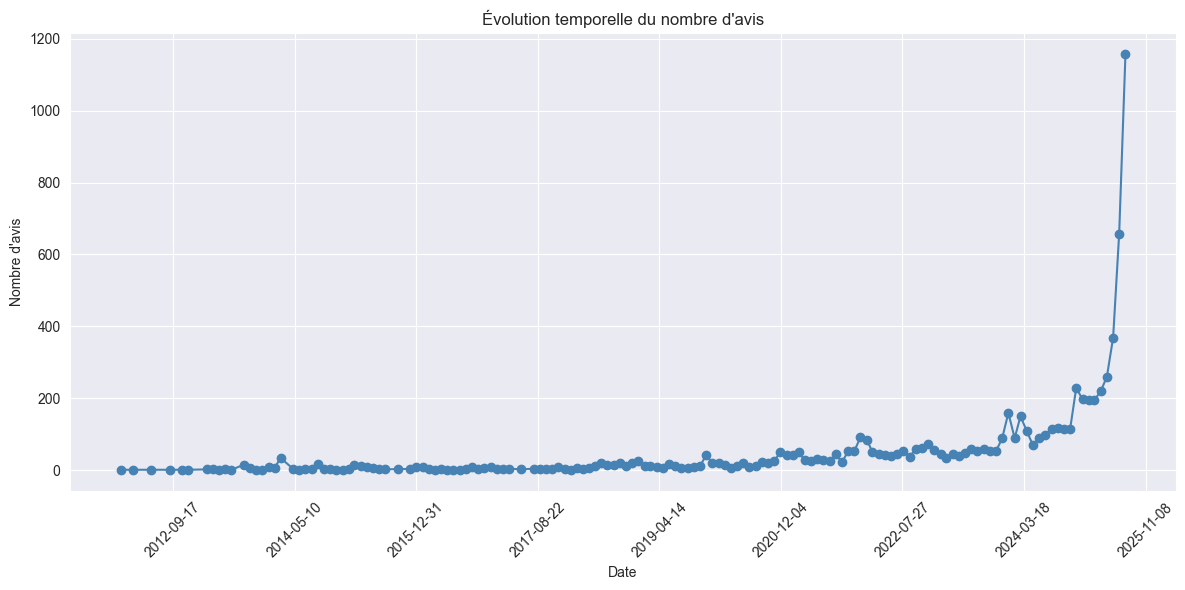

In [67]:
from matplotlib.ticker import MaxNLocator

if "datetime" in train_df.columns:
    train_df["datetime"] = pd.to_datetime(train_df["datetime"], errors="coerce")
    train_df["date"] = train_df["datetime"].dt.to_period("M").dt.to_timestamp()

    # Grouper par mois et compter
    monthly_counts = train_df.groupby("date").size()

    plt.figure(figsize=(12, 6))
    plt.plot(monthly_counts.index, monthly_counts.values, color="steelblue", marker="o")
    # Ou en barres : plt.bar(monthly_counts.index, monthly_counts.values, color="steelblue")

    plt.title("Évolution temporelle du nombre d'avis")
    plt.xlabel("Date")
    plt.ylabel("Nombre d'avis")
    plt.xticks(rotation=45)

    # Limiter le nombre de ticks sur l'axe X
    ax = plt.gca()
    ax.xaxis.set_major_locator(MaxNLocator(nbins=10))

    plt.tight_layout()
    plt.show()


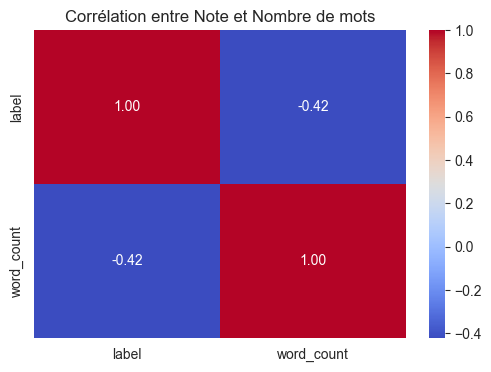

In [68]:
# Vérification d'un échantillon
train_df[['review_text', 'word_count']].head()

# Statistiques descriptives : Vérification de la distribution du nombre de mots pour repérer les valeurs extrêmes ou erreurs.
train_df['word_count'].describe()

# Création d'une table de corrélation
corr = train_df[["label","word_count"]].corr()

# Affichage la heatmap
plt.figure(figsize=(6, 4))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Corrélation entre Note et Nombre de mots')
plt.show()

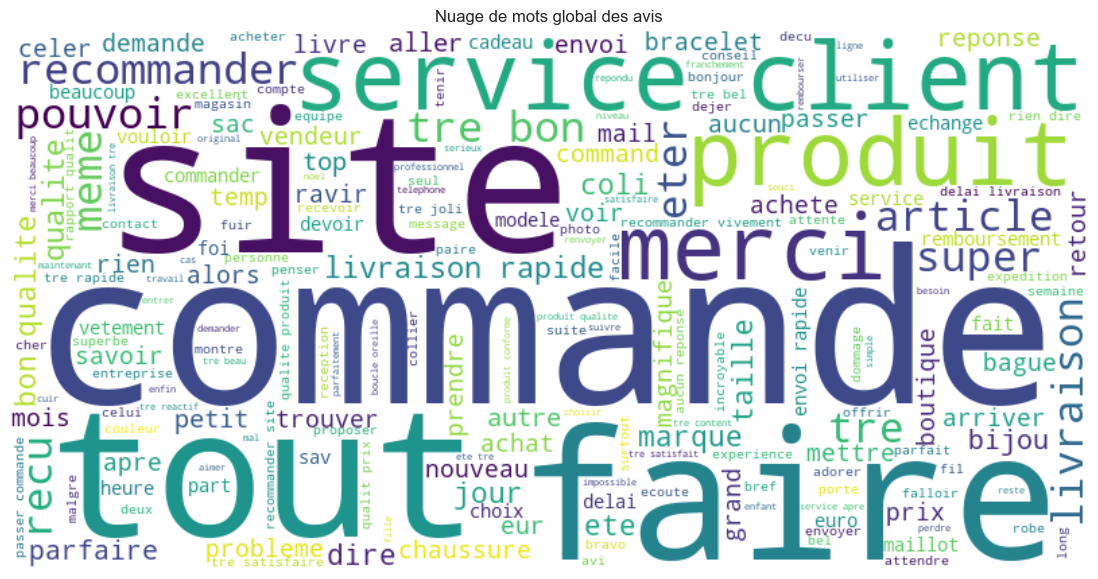

In [69]:
text = " ".join(train_df["text_ml"].astype(str))

# Génération du nuage
wordcloud = WordCloud(
    stopwords=FINAL_STOPWORDS,
    background_color="white",
    max_words=200,
    width=800,
    height=400
).generate(text)

# Affichage
plt.figure(figsize=(15,7))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis("off")
plt.title("Nuage de mots global des avis")
plt.show()


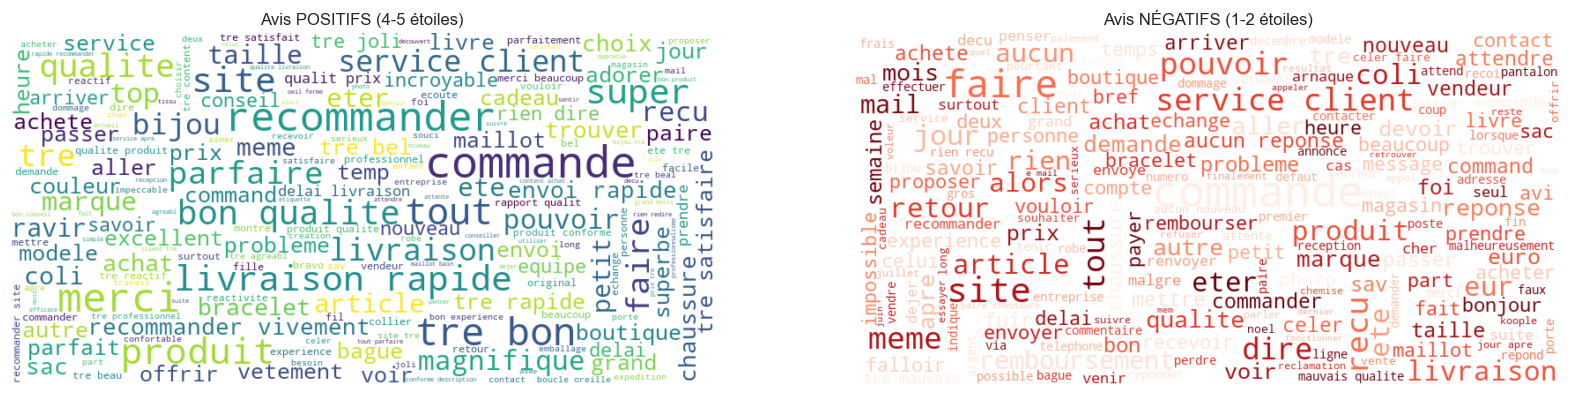

In [56]:
# Création des deux DataFrames
df_pos = train_df[train_df["label"].isin([4,5])]
df_neg = train_df[train_df["label"].isin([1,2])]

# Texte pour chaque sous-ensemble
text_pos = " ".join(df_pos["text_ml"].astype(str))
text_neg = " ".join(df_neg["text_ml"].astype(str))

# Génération des nuages
wc_pos = WordCloud(stopwords=FINAL_STOPWORDS,
                   background_color="white",
                   max_words=200,
                   max_font_size=50,
                   width=800,
                   height=400).generate(text_pos)

wc_neg = WordCloud(stopwords=FINAL_STOPWORDS,
                   background_color="white",
                   colormap="Reds",
                   max_words=200,
                   max_font_size=50,
                   width=800,
                   height=400).generate(text_neg)

# Affichage côte à côte
fig, axes = plt.subplots(1, 2, figsize=(20, 10))

axes[0].imshow(wc_pos, interpolation='bilinear')
axes[0].axis("off")
axes[0].set_title("Avis POSITIFS (4-5 étoiles)")

axes[1].imshow(wc_neg, interpolation='bilinear')
axes[1].axis("off")
axes[1].set_title("Avis NÉGATIFS (1-2 étoiles)")

plt.show()

/var/folders/zs/w920yp5j4cjfvly1235g5b_40000gn/T/ipykernel_74548/3398953020.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(y="bigram", x="freq", data=bigram_top20, palette="Blues_r")


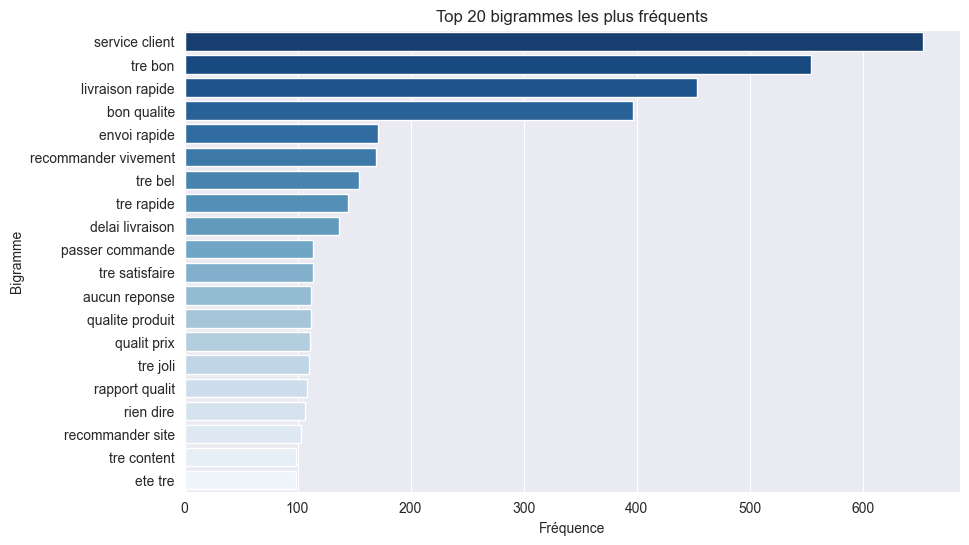

,bigram,freq
1988,service client,653
2250,tre bon,554
1142,livraison rapide,453
319,bon qualite,397
805,envoi rapide,171
1788,recommander vivement,169
2248,tre bel,154
2302,tre rapide,145
687,delai livraison,137
1380,passer commande,114


In [57]:
# Utilisation des colonnes déjà nettoyées (ici text_ml pour éviter bruit ponctuation)
vectorizer = CountVectorizer(ngram_range=(2,2), min_df=5)
X_bigrams = vectorizer.fit_transform(train_df["text_ml"].astype(str))

# Comptage de la fréquence des bigrammes
bigram_freq = np.asarray(X_bigrams.sum(axis=0)).flatten()
bigram_terms = vectorizer.get_feature_names_out()

# Top 20
bigram_df = pd.DataFrame({"bigram": bigram_terms, "freq": bigram_freq})
bigram_top20 = bigram_df.sort_values("freq", ascending=False).head(20)

# Visualisation
plt.figure(figsize=(10,6))
sns.barplot(y="bigram", x="freq", data=bigram_top20, palette="Blues_r")
plt.title("Top 20 bigrammes les plus fréquents")
plt.xlabel("Fréquence")
plt.ylabel("Bigramme")
plt.show()

bigram_top20

/Users/eko/PyCharmMiscProject/.venv/lib/python3.9/site-packages/IPython/core/pylabtools.py:152: UserWarning: Glyph 9733 (\N{BLACK STAR}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


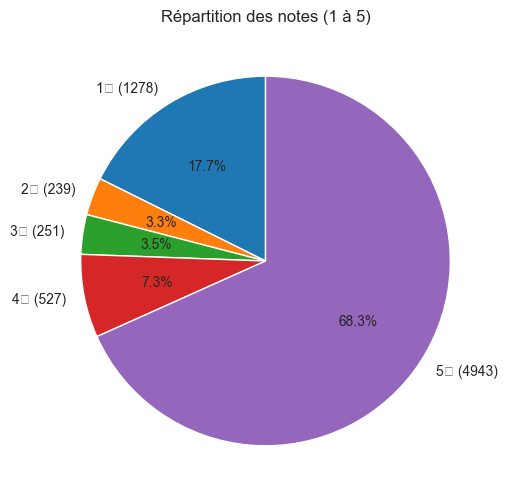

In [58]:
# Pie chart - répartition des notes
counts = train_df['rating'].value_counts().sort_index()
labels = [f"{i}★ ({counts.loc[i]})" for i in counts.index]

plt.figure(figsize=(6,6))
counts.plot.pie(autopct="%.1f%%", startangle=90, labels=labels)
plt.ylabel("")
plt.title("Répartition des notes (1 à 5)")
plt.show()


## j) Graphe supplémentaire: Nombre d’avis dans le temps
Évolution du nombre d'avis par mois
Permet d'identifier pics / baisses d'activité et potentiels événements liés à la satisfaction.

/var/folders/zs/w920yp5j4cjfvly1235g5b_40000gn/T/ipykernel_74548/860537176.py:7: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  series = df_src.set_index('datetime').resample('M').size()


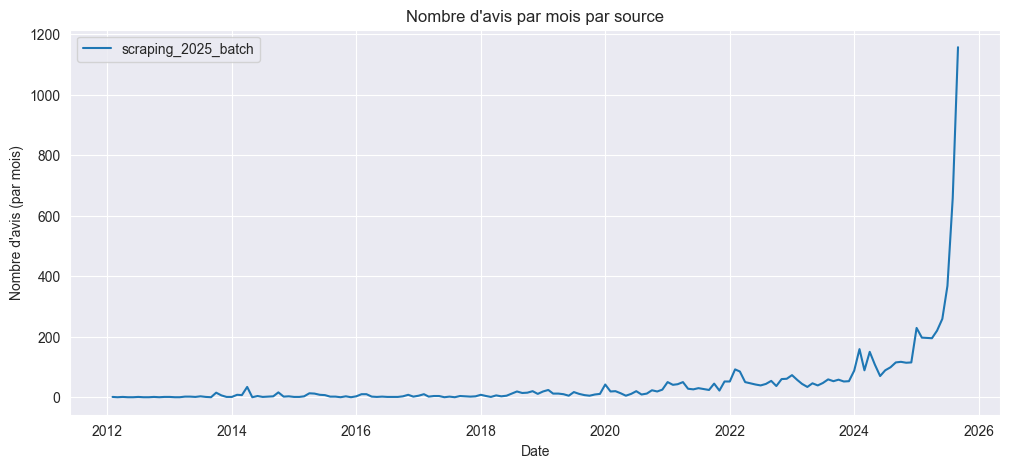

In [59]:
# Evolution temporelle des avis par mois
plt.figure(figsize=(12,5))
for src in train_df['source'].dropna().unique():
    df_src = train_df[train_df['source'] == src].copy()
    if 'datetime' in df_src.columns:
        df_src['datetime'] = pd.to_datetime(df_src['datetime'], errors='coerce')
        series = df_src.set_index('datetime').resample('M').size()
        series = series.rename(src)
        plt.plot(series.index, series.values, label=src)
plt.legend()
plt.title("Nombre d'avis par mois par source")
plt.xlabel("Date")
plt.ylabel("Nombre d'avis (par mois)")
plt.show()


## k) Graphe supplémentaire: Distribution des méta-features textuelles par note  
Nous analysons ici la distribution de quatre caractéristiques simples liées à l’intensité émotionnelle des avis :  
- **Nb exclamations**  
- **Ratio de majuscules**  
- **Nb séquences de majuscules (≥3 lettres)**  
- **Nb emojis**  

Ces signaux donnent un aperçu du style d’écriture en fonction de la satisfaction exprimée.




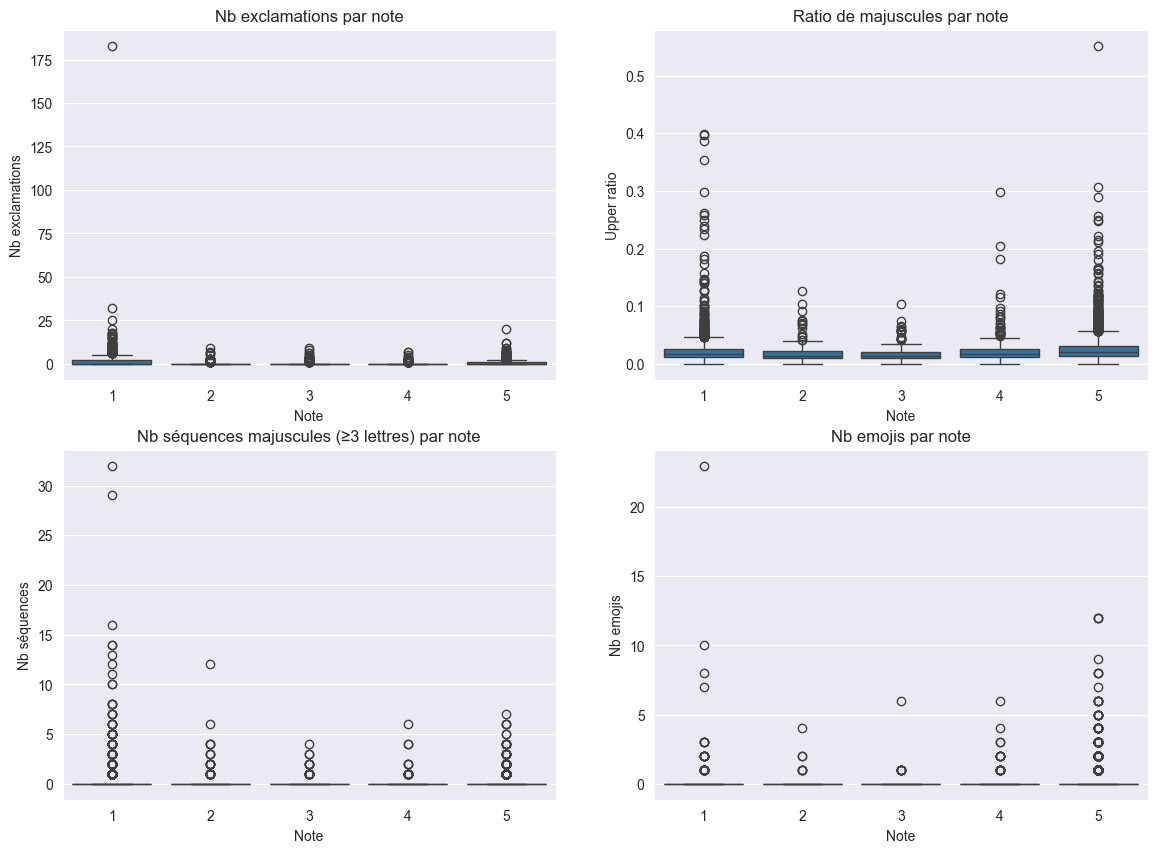

In [60]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Nb exclamations
sns.boxplot(data=train_df, x='label', y='exclam_count', ax=axes[0,0])
axes[0,0].set_title("Nb exclamations par note")
axes[0,0].set_xlabel("Note")
axes[0,0].set_ylabel("Nb exclamations")

# Ratio majuscules
sns.boxplot(data=train_df, x='label', y='upper_ratio', ax=axes[0,1])
axes[0,1].set_title("Ratio de majuscules par note")
axes[0,1].set_xlabel("Note")
axes[0,1].set_ylabel("Upper ratio")

# Séquences majuscules
sns.boxplot(data=train_df, x='label', y='upper_seq', ax=axes[1,0])
axes[1,0].set_title("Nb séquences majuscules (≥3 lettres) par note")
axes[1,0].set_xlabel("Note")
axes[1,0].set_ylabel("Nb séquences")

# Emojis
if test_df["nb_emoji"].sum() > 0:
    sns.boxplot(data=train_df, x="label", y="nb_emoji", ax=axes[1,1])
    axes[1,1].set_title("Nb emojis par note")
    axes[1,1].set_xlabel("Note")
    axes[1,1].set_ylabel("Nb emojis")
else:
    axes[1,1].text(0.5, 0.5, "Aucun emoji détecté dans le dataset",
                   ha="center", va="center", fontsize=12, color="red")
    axes[1,1].set_axis_off()


## l) Graphe supplémentaire: Heatmap mot-clé vs notes
Le Heatmap represente la fréquence relative de mots-clés par note

Cela permet d'identifier quels mots sont typiquement associés à quelles notes.

/Users/eko/PyCharmMiscProject/.venv/lib/python3.9/site-packages/sklearn/feature_extraction/text.py:402: UserWarning: Your stop_words may be inconsistent with your preprocessing. Tokenizing the stop words generated tokens ['aren', 'couldn', 'didn', 'doesn', 'don', 'hadn', 'hasn', 'haven', 'isn', 'let', 'll', 'mustn', 're', 'shan', 'shouldn', 've', 'wasn', 'weren', 'won', 'wouldn'] not in stop_words.
  warnings.warn(


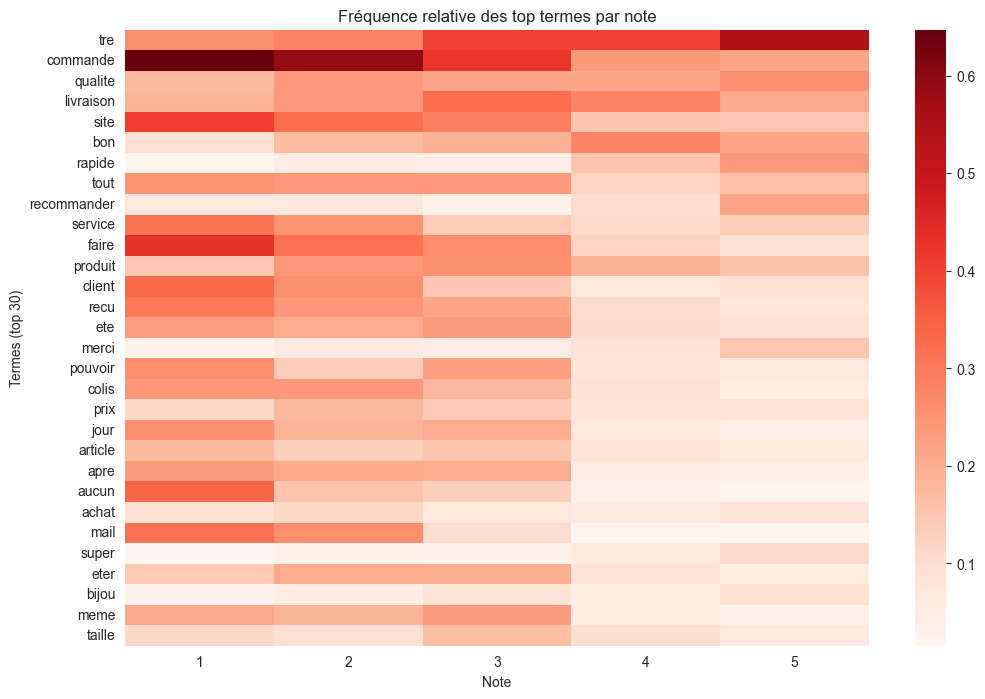

In [61]:
# Choix des top-N mots globaux
N = 30
cv = CountVectorizer(stop_words=list(FINAL_STOPWORDS), min_df=5, token_pattern=r"(?u)\b\w+\b")
X_counts = cv.fit_transform(train_df['text_ml'].astype(str))
vocab = np.array(cv.get_feature_names_out())
tot_counts = np.array(X_counts.sum(axis=0)).ravel()
top_idx = np.argsort(tot_counts)[-N:][::-1]
top_terms = vocab[top_idx]

# build a matrix term x rating
ratings = sorted(train_df['rating'].unique())
mat = np.zeros((len(top_terms), len(ratings)))
for j, r in enumerate(ratings):
    mask = train_df['rating'] == r
    if mask.sum() == 0: continue
    Xr = cv.transform(train_df.loc[mask, 'text_ml'].astype(str))
    mat[:, j] = np.array(Xr.sum(axis=0)).ravel()[top_idx] / max(1, mask.sum())

# plot heatmap
plt.figure(figsize=(12,8))
sns.heatmap(mat, yticklabels=top_terms, xticklabels=ratings, cmap="Reds", annot=False)
plt.xlabel("Note")
plt.ylabel("Termes (top 30)")
plt.title("Fréquence relative des top termes par note")
plt.show()

## m) Graphe supplémentaire: Heatmap bigrammes (top N) vs note
Pour repérer quelles expressions (bigrammes) sont caractéristiques des différentes notes, nous construisons une matrice (bigram × note) : chaque cellule contient la fréquence moyenne (par avis) du bigram dans les avis de la note correspondante. La matrice est calculée en fitant le `CountVectorizer(ngram_range=(2,2))` sur le train puis en transformant les sous-ensembles par note.


In [ ]:
#AJ Abdoul part


# ===========================
# Top bigrammes par note (heatmap)
# ===========================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_extraction.text import CountVectorizer

def plot_top_bigrams_by_rating_auto(
    df: pd.DataFrame,
    text_candidates=("text_clean","review_text","text_ml","text","title"),
    rating_candidates=("rating","service_rating","label","note","stars"),
    topN=30,
    min_df=5,
    stopwords=None,
    token_pattern=r"(?u)\b\w+\b",
    cmap="coolwarm"
):
    # ---- 1) Détection colonnes texte & note ----
    text_col = next((c for c in text_candidates if c in df.columns), None)
    rate_col = next((c for c in rating_candidates if c in df.columns), None)

    if text_col is None or rate_col is None:
        raise ValueError(
            "Colonnes introuvables.\n"
            f"- texte parmi {text_candidates}\n"
            f"- note parmi {rating_candidates}\n"
            f"Colonnes disponibles: {list(df.columns)}"
        )

    # ---- 2) Stopwords ----
    # Priorité: FINAL_STOPWORDS -> STOP_ALL -> None
    if stopwords is None:
        stopwords = (globals().get("FINAL_STOPWORDS")
                     or list(globals().get("STOP_ALL", []))
                     or None)

    # ---- 3) Préparation des données ----
    d = df[[text_col, rate_col]].copy()
    d[text_col] = d[text_col].astype(str).str.strip()
    d[rate_col] = pd.to_numeric(d[rate_col], errors="coerce")
    d = d[(d[text_col].str.len() > 0) & d[rate_col].between(1,5)]
    if d.empty:
        raise ValueError("Aucun avis exploitable après nettoyage (texte vide ou note hors [1..5]).")

    # min_df adaptatif si dataset petit
    n_docs = len(d)
    eff_min_df = min_df if n_docs >= min_df else max(1, int(0.005 * n_docs))

    # ---- 4) Vectorisation en bigrams ----
    cv_bigram = CountVectorizer(
        ngram_range=(2,2),
        stop_words=stopwords,
        min_df=eff_min_df,
        token_pattern=token_pattern
    )
    X_big = cv_bigram.fit_transform(d[text_col])
    vocab_big = np.array(cv_bigram.get_feature_names_out())
    if vocab_big.size == 0:
        raise ValueError("Vocabulaire vide : aucun bigramme trouvé (baisse min_df ou stopwords).")

    # ---- 5) Top-N bigrams globaux ----
    tot_big = np.asarray(X_big.sum(axis=0)).ravel()
    top_idx = np.argsort(tot_big)[-topN:][::-1]
    top_bigrams = vocab_big[top_idx]
    topN = len(top_bigrams)  # au cas où < topN trouvé

    # ---- 6) Matrice bigram x note (fréquence moyenne par avis) ----
    ratings = sorted(pd.Series(d[rate_col].unique()).dropna().astype(int).unique())
    mat = np.zeros((topN, len(ratings)), dtype=float)

    for j, r in enumerate(ratings):
        mask = d[rate_col] == r
        nj = int(mask.sum())
        if nj == 0:
            continue
        Xr = cv_bigram.transform(d.loc[mask, text_col])
        mat[:, j] = np.asarray(Xr.sum(axis=0)).ravel()[top_idx] / max(1, nj)

    mat_df = pd.DataFrame(mat, index=top_bigrams, columns=[f"{int(r)}★" for r in ratings])

    # ---- 7) Heatmap ----
    plt.figure(figsize=(12, 10))
    sns.heatmap(
        mat_df,
        cmap=cmap,
        center=0,
        annot=False,
        cbar_kws={'label':'Fréquence moyenne par avis'}
    )
    plt.title(f"Top {len(top_bigrams)} bigrammes vs note ({text_col})")
    plt.ylabel("Bigramme")
    plt.xlabel("Note")
    plt.tight_layout()
    plt.show()

    print(f"Colonne texte utilisée: {text_col} | Colonne note utilisée: {rate_col}")
    print(f"Docs: {n_docs} | min_df effectif: {eff_min_df} | Vocab (bigrams): {len(vocab_big)}")
    return mat_df

# ======= Utilisation =======
# Appelle directement avec le DataFrame actuel (df_raw, df_clean, train_df, etc.)
bigram_df = plot_top_bigrams_by_rating_auto(df_raw, topN=30, min_df=5)


/Users/eko/PyCharmMiscProject/.venv/lib/python3.9/site-packages/sklearn/feature_extraction/text.py:402: UserWarning: Your stop_words may be inconsistent with your preprocessing. Tokenizing the stop words generated tokens ['aren', 'couldn', 'didn', 'doesn', 'don', 'hadn', 'hasn', 'haven', 'isn', 'let', 'll', 'mustn', 're', 'shan', 'shouldn', 've', 'wasn', 'weren', 'won', 'wouldn'] not in stop_words.
  warnings.warn(


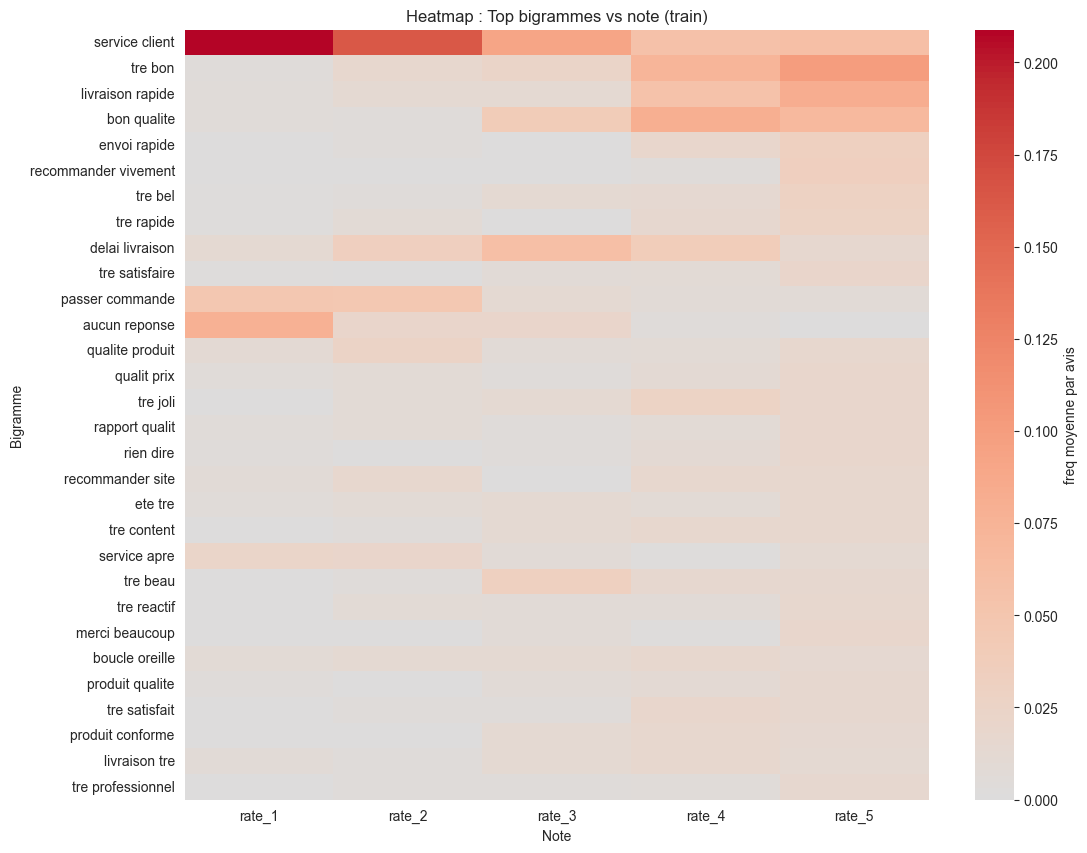

In [62]:
# Vectorizer bigram (fit sur train pour éviter fuite)
cv_bigram = CountVectorizer(ngram_range=(2,2), stop_words=list(FINAL_STOPWORDS), min_df=5, token_pattern=r"(?u)\b\w+\b")
cv_bigram.fit(train_df["text_ml"].astype(str))

# Top-N bigrams
N_big = 30
vocab_big = np.array(cv_bigram.get_feature_names_out())
X_big_train = cv_bigram.transform(train_df["text_ml"].astype(str))
tot_big = np.array(X_big_train.sum(axis=0)).ravel()
top_idx_big = np.argsort(tot_big)[-N_big:][::-1]
top_bigrams = vocab_big[top_idx_big]

# Matrice bigram x rating (normalisée par nb avis de la note)
ratings = sorted(train_df["rating"].unique())
mat_big = np.zeros((N_big, len(ratings)), dtype=float)

for j, r in enumerate(ratings):
    mask = (train_df["rating"] == r)
    if mask.sum() == 0: continue
    Xr = cv_bigram.transform(train_df.loc[mask, "text_ml"].astype(str))
    mat_big[:, j] = np.array(Xr.sum(axis=0)).ravel()[top_idx_big] / max(1, mask.sum())

mat_big_df = pd.DataFrame(mat_big, index=top_bigrams, columns=[f"rate_{int(r)}" for r in ratings])

plt.figure(figsize=(12,10))
sns.heatmap(mat_big_df, cmap="coolwarm", center=0, annot=False, cbar_kws={'label':'freq moyenne par avis'})
plt.title("Heatmap : Top bigrammes vs note (train)")
plt.ylabel("Bigramme")
plt.xlabel("Note")
plt.show()